In [ ]:
# Project Paths and Backup

In [2]:
from pathlib import Path
from datetime import datetime
import shutil
import pandas as pd
import joblib

# Project root
BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

# Existing project files
MODEL_V4 = BASE_DIR / "models" / "it_helpdesk_classifier_v4.pkl"

TRAIN_PATH = (
    BASE_DIR / "dataset" / "processed"
    / "training_dataset_v5_leakage_free.csv"
)

TEST_PATH = (
    BASE_DIR / "dataset" / "processed"
    / "expanded_classification_test_template.csv"
)

RESULTS_DIR = BASE_DIR / "results"
MODELS_DIR = BASE_DIR / "models"

# Backup directory
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

BACKUP_DIR = BASE_DIR / "documentation" / "v5_experiment_backups" / timestamp
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

# Verify files
required_files = {
    "V4 model": MODEL_V4,
    "Training dataset": TRAIN_PATH,
    "Independent test dataset": TEST_PATH
}

print("===== FILE VERIFICATION =====")

for name, path in required_files.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")
    print(path)

missing_files = [
    name for name, path in required_files.items()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing required project files: {missing_files}"
    )

# Create backups
for name, path in required_files.items():
    destination = BACKUP_DIR / path.name
    shutil.copy2(path, destination)
    print(f"Backup created: {destination}")

print("\n===== BACKUP COMPLETED =====")
print("Backup folder:", BACKUP_DIR)


===== FILE VERIFICATION =====
V4 model: FOUND
D:\AI_IT_HELPDESK\models\it_helpdesk_classifier_v4.pkl
Training dataset: FOUND
D:\AI_IT_HELPDESK\dataset\processed\training_dataset_v5_leakage_free.csv
Independent test dataset: FOUND
D:\AI_IT_HELPDESK\dataset\processed\expanded_classification_test_template.csv
Backup created: D:\AI_IT_HELPDESK\documentation\v5_experiment_backups\20261104_114011\it_helpdesk_classifier_v4.pkl
Backup created: D:\AI_IT_HELPDESK\documentation\v5_experiment_backups\20261104_114011\training_dataset_v5_leakage_free.csv
Backup created: D:\AI_IT_HELPDESK\documentation\v5_experiment_backups\20261104_114011\expanded_classification_test_template.csv

===== BACKUP COMPLETED =====
Backup folder: D:\AI_IT_HELPDESK\documentation\v5_experiment_backups\20261104_114011


In [ ]:
# Dataset Validation

In [3]:
import pandas as pd
import re

# Load training and independent test datasets
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

# Normalize query for duplicate checking
def normalize_query(text):
    text = str(text).lower().strip()
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text

# Validate required columns
required_columns = ["user_query", "category"]

for column in required_columns:
    if column not in train_df.columns:
        raise ValueError(f"Training dataset missing: {column}")

    if column not in test_df.columns:
        raise ValueError(f"Test dataset missing: {column}")

# Missing values
print("===== V5 DATASET QUALITY CHECK =====")

print("\nTraining records:", len(train_df))
print("Test records:", len(test_df))

print("\nTraining missing values:")
print(train_df[required_columns].isnull().sum())

print("\nTest missing values:")
print(test_df[required_columns].isnull().sum())

# Duplicate query check
train_df["normalized_query"] = (
    train_df["user_query"].apply(normalize_query)
)

test_df["normalized_query"] = (
    test_df["user_query"].apply(normalize_query)
)

print("\nTraining duplicate queries:",
      train_df["normalized_query"].duplicated().sum())

print("Test duplicate queries:",
      test_df["normalized_query"].duplicated().sum())

# Exact normalized overlap
overlap = set(train_df["normalized_query"]) & set(
    test_df["normalized_query"]
)

print("\nTraining/Test exact query overlap:", len(overlap))

# Category distribution
print("\n===== TRAINING CATEGORY DISTRIBUTION =====")

category_distribution = (
    train_df["category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Records")
)

display(category_distribution)

print("\n===== TEST CATEGORY DISTRIBUTION =====")

display(test_df["category"].value_counts())

# Category validation
expected_categories = {
    "Account & Password",
    "Network & VPN",
    "Printer",
    "Software",
    "System Health"
}

actual_categories = set(train_df["category"].dropna().unique())

print("\nAll five categories present:",
      expected_categories.issubset(actual_categories))


===== V5 DATASET QUALITY CHECK =====

Training records: 162
Test records: 50

Training missing values:
user_query    0
category      0
dtype: int64

Test missing values:
user_query    0
category      0
dtype: int64

Training duplicate queries: 0
Test duplicate queries: 0

Training/Test exact query overlap: 0

===== TRAINING CATEGORY DISTRIBUTION =====


,Category,Records
0,Network & VPN,40
1,Printer,37
2,System Health,30
3,Software,28
4,Account & Password,27



===== TEST CATEGORY DISTRIBUTION =====


category
Account & Password    10
Network & VPN         10
Printer               10
Software              10
System Health         10
Name: count, dtype: int64


All five categories present: True


In [ ]:
# Train and Compare V5 Candidates

In [4]:
import numpy as np
import pandas as pd
import joblib

from pathlib import Path

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold, cross_validate

# --------------------------------------------------
# 1. Load training dataset only
# --------------------------------------------------

train_df = pd.read_csv(TRAIN_PATH)

X_train = train_df["user_query"].astype(str)
y_train = train_df["category"].astype(str)

# --------------------------------------------------
# 2. Define models
# --------------------------------------------------

logistic_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

calibrated_svm_model = CalibratedClassifierCV(
    estimator=clone(svm_model),
    method="sigmoid",
    cv=3
)

models = {
    "Logistic Regression": logistic_model,
    "Linear SVM": svm_model,
    "Calibrated Linear SVM": calibrated_svm_model
}

# --------------------------------------------------
# 3. Stratified 5-Fold Cross Validation
# --------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

results = []

print("===== V5 MODEL CROSS-VALIDATION =====")
print("Training records:", len(X_train))
print("Cross-validation folds: 5")

for model_name, model in models.items():

    print(f"\nEvaluating: {model_name}")

    cv_results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1
    )

    results.append({
        "Model": model_name,
        "Accuracy_Mean": np.mean(cv_results["test_accuracy"]),
        "Accuracy_Std": np.std(cv_results["test_accuracy"]),
        "Macro_Precision": np.mean(
            cv_results["test_precision_macro"]
        ),
        "Macro_Recall": np.mean(
            cv_results["test_recall_macro"]
        ),
        "Macro_F1": np.mean(cv_results["test_f1_macro"]),
        "Macro_F1_Std": np.std(cv_results["test_f1_macro"])
    })

    print("Mean Accuracy:",
          round(np.mean(cv_results["test_accuracy"]), 4))

    print("Mean Macro F1:",
          round(np.mean(cv_results["test_f1_macro"]), 4))

# --------------------------------------------------
# 4. Display comparison
# --------------------------------------------------

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="Macro_F1",
    ascending=False
).reset_index(drop=True)

print("\n===== V5 CROSS-VALIDATION COMPARISON =====")

display(comparison_df)

# --------------------------------------------------
# 5. Save results
# --------------------------------------------------

comparison_path = (
    RESULTS_DIR / "v5_cross_validation_comparison.csv"
)

comparison_df.to_csv(comparison_path, index=False)

print("\nResults saved:")
print(comparison_path)

===== V5 MODEL CROSS-VALIDATION =====
Training records: 162
Cross-validation folds: 5

Evaluating: Logistic Regression
Mean Accuracy: 0.9193
Mean Macro F1: 0.9158

Evaluating: Linear SVM
Mean Accuracy: 0.9314
Mean Macro F1: 0.9291

Evaluating: Calibrated Linear SVM
Mean Accuracy: 0.9254
Mean Macro F1: 0.9224

===== V5 CROSS-VALIDATION COMPARISON =====


,Model,Accuracy_Mean,Accuracy_Std,Macro_Precision,Macro_Recall,Macro_F1,Macro_F1_Std
0,Linear SVM,0.931439,0.063850,0.936746,0.927905,0.929087,0.067322
1,Calibrated Linear SVM,0.925379,0.061319,0.930079,0.921238,0.922420,0.064528
2,Logistic Regression,0.919318,0.054795,0.925317,0.914905,0.915822,0.058080



Results saved:
D:\AI_IT_HELPDESK\results\v5_cross_validation_comparison.csv


In [ ]:
# Select and Save Best V5 Model

In [5]:
# Select the best candidate using CV Macro F1
best_model_name = comparison_df.iloc[0]["Model"]

best_model = clone(models[best_model_name])

print("===== V5 BEST MODEL SELECTION =====")
print("Selected model:", best_model_name)

# Train using complete training dataset
best_model.fit(X_train, y_train)

# Save without overwriting V4
V5_MODEL_PATH = (
    MODELS_DIR / "it_helpdesk_classifier_v5.pkl"
)

joblib.dump(best_model, V5_MODEL_PATH)

print("\nV5 model training completed.")
print("Model saved:", V5_MODEL_PATH)
print("Model exists:", V5_MODEL_PATH.exists())

print("\nV5 model classes:")
print(best_model.classes_)


===== V5 BEST MODEL SELECTION =====
Selected model: Linear SVM

V5 model training completed.
Model saved: D:\AI_IT_HELPDESK\models\it_helpdesk_classifier_v5.pkl
Model exists: True

V5 model classes:
['Account & Password' 'Network & VPN' 'Printer' 'Software' 'System Health']


In [ ]:
# Load models and test dataset

In [6]:

from pathlib import Path
import pandas as pd
import numpy as np
import joblib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix
)

# Project paths
BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

V4_MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier_v4.pkl"
V5_MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier_v5.pkl"

TEST_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "expanded_classification_test_template.csv"
)

RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Verify files
for path in [V4_MODEL_PATH, V5_MODEL_PATH, TEST_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path}")

# Load models
v4_model = joblib.load(V4_MODEL_PATH)
v5_model = joblib.load(V5_MODEL_PATH)

# Load independent test data
test_df = pd.read_csv(TEST_PATH)

required_columns = {"user_query", "category"}

if not required_columns.issubset(test_df.columns):
    raise ValueError(
        f"Test dataset must contain columns: {required_columns}"
    )

test_df = test_df.dropna(
    subset=["user_query", "category"]
).copy()

X_test = test_df["user_query"].astype(str)
y_test = test_df["category"].astype(str)

print("===== V4 VS V5 FILE VERIFICATION =====")
print("V4 model loaded:", type(v4_model))
print("V5 model loaded:", type(v5_model))
print("Independent test records:", len(test_df))
print("V4 classes:", v4_model.classes_)
print("V5 classes:", v5_model.classes_)


===== V4 VS V5 FILE VERIFICATION =====
V4 model loaded: <class 'sklearn.pipeline.Pipeline'>
V5 model loaded: <class 'sklearn.pipeline.Pipeline'>
Independent test records: 50
V4 classes: ['Account & Password' 'Network & VPN' 'Printer' 'Software' 'System Health']
V5 classes: ['Account & Password' 'Network & VPN' 'Printer' 'Software' 'System Health']


In [ ]:
# Generate predictions and calculate metrics

In [8]:
from pathlib import Path
import pandas as pd
import numpy as np
import joblib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef
)

# Project paths
BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

V4_MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier_v4.pkl"
V5_MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier_v5.pkl"

TEST_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "expanded_classification_test_template.csv"
)

RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Load models
v4_model = joblib.load(V4_MODEL_PATH)
v5_model = joblib.load(V5_MODEL_PATH)

# Load test data
test_df = pd.read_csv(TEST_PATH)
test_df = test_df.dropna(
    subset=["user_query", "category"]
).copy()

X_test = test_df["user_query"].astype(str)
y_test = test_df["category"].astype(str)

# Generate predictions
v4_predictions = v4_model.predict(X_test)
v5_predictions = v5_model.predict(X_test)

# Calculate metrics
def calculate_metrics(model_name, actual, predicted):
    return {
        "Model": model_name,
        "Test_Records": len(actual),
        "Accuracy": accuracy_score(actual, predicted),
        "Macro_Precision": precision_score(
            actual, predicted, average="macro", zero_division=0
        ),
        "Macro_Recall": recall_score(
            actual, predicted, average="macro", zero_division=0
        ),
        "Macro_F1": f1_score(
            actual, predicted, average="macro", zero_division=0
        ),
        "Balanced_Accuracy": balanced_accuracy_score(
            actual, predicted
        ),
        "MCC": matthews_corrcoef(actual, predicted)
    }

comparison = pd.DataFrame([
    calculate_metrics("V4 - Existing Model", y_test, v4_predictions),
    calculate_metrics("V5 - New Linear SVM", y_test, v5_predictions)
])

print("===== V4 VS V5 INDEPENDENT TEST COMPARISON =====")
display(comparison.round(4))

# Save results
metrics_path = (
    RESULTS_DIR / "v4_v5_independent_test_comparison.csv"
)
comparison.to_csv(metrics_path, index=False)

print("\nComparison saved:", metrics_path)
print("V4 predictions:", len(v4_predictions))
print("V5 predictions:", len(v5_predictions))


===== V4 VS V5 INDEPENDENT TEST COMPARISON =====


,Model,Test_Records,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Balanced_Accuracy,MCC
0,V4 - Existing Model,50,0.9,0.9022,0.9,0.8987,0.9,0.8763
1,V5 - New Linear SVM,50,0.9,0.9022,0.9,0.8987,0.9,0.8763



Comparison saved: D:\AI_IT_HELPDESK\results\v4_v5_independent_test_comparison.csv
V4 predictions: 50
V5 predictions: 50


===== V4 CLASSIFICATION REPORT =====
                    precision    recall  f1-score   support

Account & Password       1.00      1.00      1.00        10
     Network & VPN       0.89      0.80      0.84        10
           Printer       0.89      0.80      0.84        10
          Software       0.90      0.90      0.90        10
     System Health       0.83      1.00      0.91        10

          accuracy                           0.90        50
         macro avg       0.90      0.90      0.90        50
      weighted avg       0.90      0.90      0.90        50

===== V5 CLASSIFICATION REPORT =====
                    precision    recall  f1-score   support

Account & Password       1.00      1.00      1.00        10
     Network & VPN       0.89      0.80      0.84        10
           Printer       0.89      0.80      0.84        10
          Software       0.90      0.90      0.90        10
     System Health       0.83      1.00      0.91        10

          accuracy   

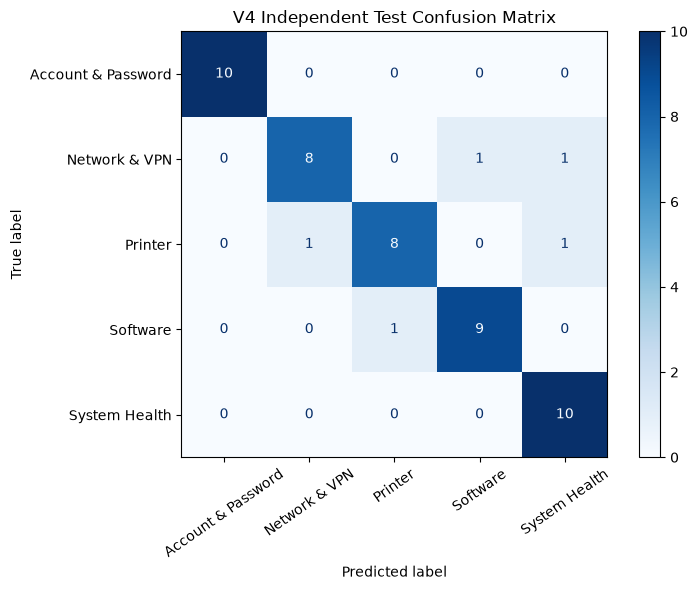

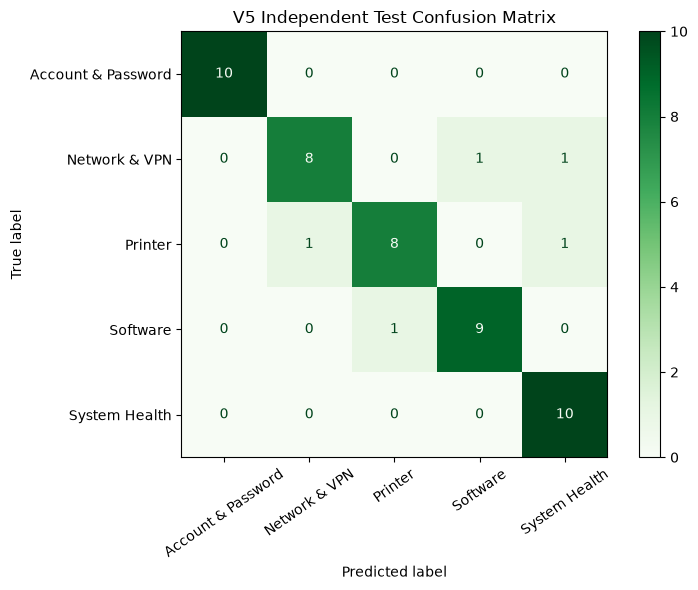

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = sorted(y_test.unique())

print("===== V4 CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    v4_predictions,
    labels=labels,
    zero_division=0
))

print("===== V5 CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    v5_predictions,
    labels=labels,
    zero_division=0
))

# V4 confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    v4_predictions,
    labels=labels,
    display_labels=labels,
    cmap="Blues",
    xticks_rotation=35,
    ax=ax
)

ax.set_title("V4 Independent Test Confusion Matrix")
plt.tight_layout()
plt.show()

# V5 confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    v5_predictions,
    labels=labels,
    display_labels=labels,
    cmap="Greens",
    xticks_rotation=35,
    ax=ax
)

ax.set_title("V5 Independent Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:
# Identify prediction changes

In [10]:
prediction_comparison = test_df[
    ["user_query", "category"]
].copy()

prediction_comparison["V4_Prediction"] = v4_predictions
prediction_comparison["V5_Prediction"] = v5_predictions

prediction_comparison["V4_Correct"] = (
    prediction_comparison["category"] ==
    prediction_comparison["V4_Prediction"]
)

prediction_comparison["V5_Correct"] = (
    prediction_comparison["category"] ==
    prediction_comparison["V5_Prediction"]
)

prediction_comparison["Prediction_Changed"] = (
    prediction_comparison["V4_Prediction"] !=
    prediction_comparison["V5_Prediction"]
)

print("===== PREDICTION CHANGE ANALYSIS =====")
print(
    "Predictions changed:",
    prediction_comparison["Prediction_Changed"].sum()
)

print(
    "V5 corrected errors:",
    (
        (~prediction_comparison["V4_Correct"]) &
        prediction_comparison["V5_Correct"]
    ).sum()
)

print(
    "V5 introduced new errors:",
    (
        prediction_comparison["V4_Correct"] &
        (~prediction_comparison["V5_Correct"])
    ).sum()
)

display(
    prediction_comparison[
        prediction_comparison["Prediction_Changed"]
    ]
)

prediction_path = RESULTS_DIR / "v4_v5_prediction_comparison.csv"
prediction_comparison.to_csv(prediction_path, index=False)

print("Prediction comparison saved:", prediction_path)

===== PREDICTION CHANGE ANALYSIS =====
Predictions changed: 0
V5 corrected errors: 0
V5 introduced new errors: 0


,user_query,category,V4_Prediction,V5_Prediction,V4_Correct,V5_Correct,Prediction_Changed


Prediction comparison saved: D:\AI_IT_HELPDESK\results\v4_v5_prediction_comparison.csv


In [ ]:
#Check probability support

In [11]:
print("===== V4 / V5 CONFIDENCE SUPPORT =====")

print("\nV4 model:")
print("Model type:", type(v4_model))
print("predict_proba available:", hasattr(v4_model, "predict_proba"))
print("decision_function available:", hasattr(v4_model, "decision_function"))

print("\nV5 model:")
print("Model type:", type(v5_model))
print("predict_proba available:", hasattr(v5_model, "predict_proba"))
print("decision_function available:", hasattr(v5_model, "decision_function"))

# Check V4 probability output
if hasattr(v4_model, "predict_proba"):
    v4_probabilities = v4_model.predict_proba(X_test)

    v4_confidence = np.max(v4_probabilities, axis=1) * 100

    print("\nV4 probability matrix shape:", v4_probabilities.shape)
    print("V4 average confidence:", round(v4_confidence.mean(), 2))
    print("V4 minimum confidence:", round(v4_confidence.min(), 2))
    print("V4 maximum confidence:", round(v4_confidence.max(), 2))

# Check V5 probability output
if hasattr(v5_model, "predict_proba"):
    v5_probabilities = v5_model.predict_proba(X_test)

    v5_confidence = np.max(v5_probabilities, axis=1) * 100

    print("\nV5 probability matrix shape:", v5_probabilities.shape)
    print("V5 average confidence:", round(v5_confidence.mean(), 2))
else:
    print("\nV5 does not provide predict_proba().")
    print("Its decision scores must not be treated as probabilities.")


===== V4 / V5 CONFIDENCE SUPPORT =====

V4 model:
Model type: <class 'sklearn.pipeline.Pipeline'>
predict_proba available: True
decision_function available: False

V5 model:
Model type: <class 'sklearn.pipeline.Pipeline'>
predict_proba available: False
decision_function available: True

V4 probability matrix shape: (50, 5)
V4 average confidence: 79.3
V4 minimum confidence: 33.71
V4 maximum confidence: 95.32

V5 does not provide predict_proba().
Its decision scores must not be treated as probabilities.


In [ ]:
# V4 confidence threshold evaluation

In [12]:
if not hasattr(v4_model, "predict_proba"):
    raise ValueError(
        "V4 does not support predict_proba(). "
        "Check the calibration pipeline before proceeding."
    )

confidence_df = pd.DataFrame({
    "Actual_Category": y_test.to_numpy(),
    "Predicted_Category": v4_predictions,
    "Confidence": v4_confidence
})

threshold_results = []

for threshold in [60, 70, 80]:

    accepted = confidence_df[
        confidence_df["Confidence"] >= threshold
    ]

    review = confidence_df[
        confidence_df["Confidence"] < threshold
    ]

    accepted_accuracy = (
        accuracy_score(
            accepted["Actual_Category"],
            accepted["Predicted_Category"]
        ) * 100
        if len(accepted) > 0 else 0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Accepted_Predictions": len(accepted),
        "Human_Review": len(review),
        "Coverage_Percentage": len(accepted) / len(confidence_df) * 100,
        "Accuracy_Of_Accepted": accepted_accuracy
    })

threshold_df = pd.DataFrame(threshold_results)

print("===== V4 CONFIDENCE THRESHOLD ANALYSIS =====")
display(threshold_df.round(2))

threshold_path = (
    RESULTS_DIR / "v4_confidence_threshold_analysis.csv"
)

threshold_df.to_csv(threshold_path, index=False)

print("Saved:", threshold_path)


===== V4 CONFIDENCE THRESHOLD ANALYSIS =====


,Threshold,Accepted_Predictions,Human_Review,Coverage_Percentage,Accuracy_Of_Accepted
0,60,44,6,88.0,95.45
1,70,38,12,76.0,100.00
2,80,32,18,64.0,100.00


Saved: D:\AI_IT_HELPDESK\results\v4_confidence_threshold_analysis.csv


In [ ]:
# Calculate calibration metrics

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import log_loss
from sklearn.preprocessing import label_binarize

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
RESULTS_DIR = BASE_DIR / "results"

V4_MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier_v4.pkl"
TEST_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "expanded_classification_test_template.csv"
)

# Load V4 model and independent test dataset
v4_model = joblib.load(V4_MODEL_PATH)

test_df = pd.read_csv(TEST_PATH).dropna(
    subset=["user_query", "category"]
).copy()

X_test = test_df["user_query"].astype(str)
y_test = test_df["category"].astype(str)

# Get probabilities
probabilities = v4_model.predict_proba(X_test)
classes = v4_model.classes_

# Convert actual categories to one-hot format
y_binary = label_binarize(y_test, classes=classes)

# Multiclass Brier score
brier_score = np.mean(
    np.sum((probabilities - y_binary) ** 2, axis=1)
)

# Log loss
model_log_loss = log_loss(
    y_test,
    probabilities,
    labels=classes
)

# Average confidence
confidence = np.max(probabilities, axis=1)

# Prediction accuracy
predictions = v4_model.predict(X_test)
correct = (predictions == y_test.to_numpy())

print("===== V4 CALIBRATION METRICS =====")
print("Test records:", len(y_test))
print("Multiclass Brier Score:", round(brier_score, 4))
print("Log Loss:", round(model_log_loss, 4))
print("Average confidence:", round(confidence.mean() * 100, 2), "%")
print("Actual accuracy:", round(correct.mean() * 100, 2), "%")

calibration_metrics = pd.DataFrame([{
    "Model": "V4 Calibrated Linear SVM",
    "Test_Records": len(y_test),
    "Multiclass_Brier_Score": brier_score,
    "Log_Loss": model_log_loss,
    "Average_Confidence_Percentage": confidence.mean() * 100,
    "Actual_Accuracy_Percentage": correct.mean() * 100
}])

calibration_metrics.to_csv(
    RESULTS_DIR / "v4_calibration_metrics.csv",
    index=False
)

display(calibration_metrics.round(4))
print("Calibration metrics saved.")


===== V4 CALIBRATION METRICS =====
Test records: 50
Multiclass Brier Score: 0.1376
Log Loss: 0.3098
Average confidence: 79.3 %
Actual accuracy: 90.0 %


,Model,Test_Records,Multiclass_Brier_Score,Log_Loss,Average_Confidence_Percentage,Actual_Accuracy_Percentage
0,V4 Calibrated Linear SVM,50,0.1376,0.3098,79.304,90.0


Calibration metrics saved.


In [ ]:
# Plot multiclass calibration curves

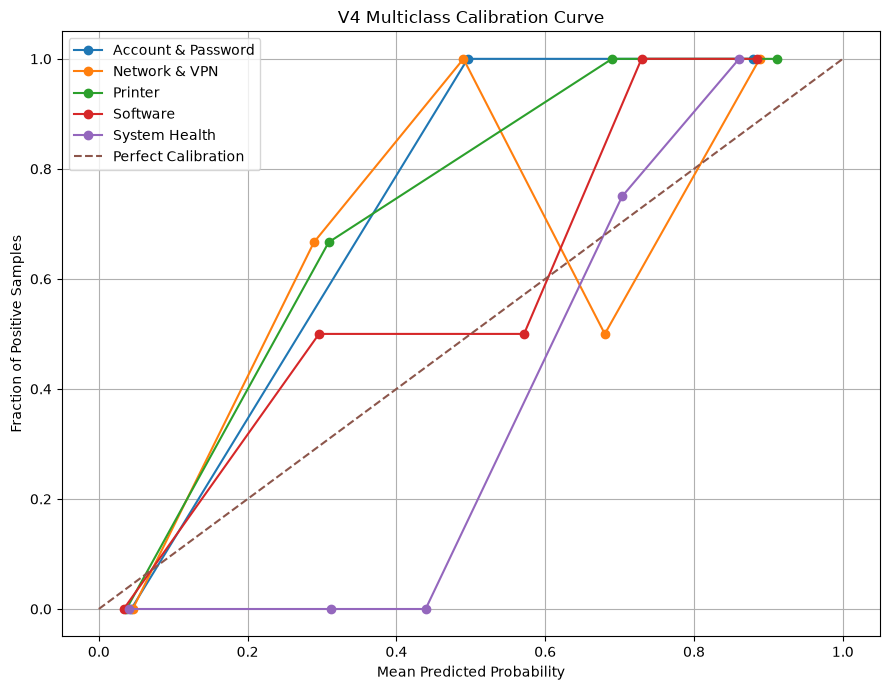

Calibration curve saved: D:\AI_IT_HELPDESK\results\v4_calibration_curve.png


In [14]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

plt.figure(figsize=(9, 7))

# One-vs-rest calibration curves
for i, category in enumerate(classes):

    fraction_positive, mean_predicted = calibration_curve(
        y_binary[:, i],
        probabilities[:, i],
        n_bins=5,
        strategy="uniform"
    )

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=category
    )

# Perfect calibration reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positive Samples")
plt.title("V4 Multiclass Calibration Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()

plot_path = RESULTS_DIR / "v4_calibration_curve.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Calibration curve saved:", plot_path)


In [ ]:
# Final Model Integration Verification – Verify current application model reference

In [15]:
from pathlib import Path
import re

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
APP_PATH = BASE_DIR / "frontend" / "app.py"

print("===== STEP 20.8: APP MODEL VERIFICATION =====")

if not APP_PATH.exists():
    raise FileNotFoundError(f"Application not found: {APP_PATH}")

app_text = APP_PATH.read_text(encoding="utf-8")

for line_number, line in enumerate(app_text.splitlines(), start=1):
    if any(term in line.upper() for term in [
        "MODEL_PATH", "JOBLIB.LOAD", "CLASSIFIER ="
    ]):
        print(f"Line {line_number}: {line.strip()}")

print("\n===== MODEL FILE CHECK =====")

for version in ["v4", "v5"]:
    model_path = BASE_DIR / "models" / f"it_helpdesk_classifier_{version}.pkl"
    print(f"{version.upper()} model exists:", model_path.exists())


===== STEP 20.8: APP MODEL VERIFICATION =====
Line 20: MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier_v4.pkl"
Line 656: def load_ai_components(model_path, vector_dir, model_version):
Line 658: classifier = joblib.load(model_path)
Line 679: str(MODEL_PATH),
Line 681: MODEL_PATH.stat().st_mtime_ns
Line 685: f"Loaded model: {MODEL_PATH.name}"

===== MODEL FILE CHECK =====
V4 model exists: True
V5 model exists: True


In [ ]:
# Application prediction verification

In [16]:
import joblib
import numpy as np
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier_v4.pkl"

model = joblib.load(MODEL_PATH)

test_queries = [
    "My office printer is offline.",
    "I cannot connect to the company VPN.",
    "My Windows password has expired.",
    "Microsoft Excel is crashing.",
    "My computer is running very slowly."
]

results = []

for query in test_queries:
    probabilities = model.predict_proba([query])[0]
    predicted_index = np.argmax(probabilities)

    results.append({
        "User_Query": query,
        "Predicted_Category": model.classes_[predicted_index],
        "Confidence_Percentage": round(
            probabilities[predicted_index] * 100, 2
        ),
        "Human_Review_Required": (
            probabilities[predicted_index] < 0.70
        )
    })

import pandas as pd

verification_df = pd.DataFrame(results)
display(verification_df)

output_path = BASE_DIR / "results" / "v4_application_verification.csv"
verification_df.to_csv(output_path, index=False)

print("Saved:", output_path)


,User_Query,Predicted_Category,Confidence_Percentage,Human_Review_Required
0,My office printer is offline.,Printer,91.02,False
1,I cannot connect to the company VPN.,Network & VPN,91.54,False
2,My Windows password has expired.,Account & Password,80.15,False
3,Microsoft Excel is crashing.,Software,71.73,False
4,My computer is running very slowly.,System Health,89.92,False


Saved: D:\AI_IT_HELPDESK\results\v4_application_verification.csv


In [ ]:
# Local deployment preparation– Verify deployment files

In [17]:
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

required_files = {
    "Streamlit Application": BASE_DIR / "frontend" / "app.py",
    "V4 Classifier": BASE_DIR / "models" / "it_helpdesk_classifier_v4.pkl",
    "Database": BASE_DIR / "database" / "helpdesk.db",
    "Knowledge Base": BASE_DIR / "knowledge_base" / "it_knowledge_base.csv",
    "Training Dataset": BASE_DIR / "dataset" / "processed" / "training_dataset_v5_leakage_free.csv"
}

print("===== STEP 20.10: DEPLOYMENT FILE CHECK =====")

all_found = True

for name, path in required_files.items():
    exists = path.exists()
    print(f"{name}: {'FOUND' if exists else 'MISSING'}")
    print(path)

    if not exists:
        all_found = False

print("\nDeployment file verification:",
      "PASSED" if all_found else "CHECK REQUIRED")


===== STEP 20.10: DEPLOYMENT FILE CHECK =====
Streamlit Application: FOUND
D:\AI_IT_HELPDESK\frontend\app.py
V4 Classifier: FOUND
D:\AI_IT_HELPDESK\models\it_helpdesk_classifier_v4.pkl
Database: FOUND
D:\AI_IT_HELPDESK\database\helpdesk.db
Knowledge Base: FOUND
D:\AI_IT_HELPDESK\knowledge_base\it_knowledge_base.csv
Training Dataset: FOUND
D:\AI_IT_HELPDESK\dataset\processed\training_dataset_v5_leakage_free.csv

Deployment file verification: PASSED


In [ ]:
# Verify Python dependencies

In [18]:
import importlib.util
import sys

required_packages = [
    "streamlit",
    "pandas",
    "numpy",
    "sklearn",
    "joblib",
    "sqlite3",
    "chromadb",
    "sentence_transformers",
    "bcrypt"
]

print("===== DEPENDENCY VERIFICATION =====")
print("Python executable:", sys.executable)

missing_packages = []

for package in required_packages:
    available = importlib.util.find_spec(package) is not None

    print(f"{package}: {'INSTALLED' if available else 'MISSING'}")

    if not available:
        missing_packages.append(package)

print("\nMissing packages:", missing_packages)


===== DEPENDENCY VERIFICATION =====
Python executable: C:\Users\Nimesh\anaconda3\python.exe
streamlit: INSTALLED
pandas: INSTALLED
numpy: INSTALLED
sklearn: INSTALLED
joblib: INSTALLED
sqlite3: INSTALLED
chromadb: INSTALLED
sentence_transformers: INSTALLED
bcrypt: INSTALLED

Missing packages: []


In [ ]:
# Launch local application

In [19]:
from pathlib import Path
import subprocess
import sys

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
APP_PATH = BASE_DIR / "frontend" / "app.py"

if not APP_PATH.exists():
    raise FileNotFoundError(APP_PATH)

process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "streamlit",
        "run",
        str(APP_PATH),
        "--server.port=8501",
        "--server.address=127.0.0.1"
    ],
    cwd=str(APP_PATH.parent)
)

print("Local deployment started.")
print("Application URL: http://localhost:8501")
print("Process ID:", process.pid)


Local deployment started.
Application URL: http://localhost:8501
Process ID: 24084


In [ ]:
# Launch local deployment– Start Streamlit

In [20]:
from pathlib import Path
import subprocess
import sys

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
APP_PATH = BASE_DIR / "frontend" / "app.py"

if not APP_PATH.exists():
    raise FileNotFoundError(APP_PATH)

process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "streamlit",
        "run",
        str(APP_PATH),
        "--server.port=8501",
        "--server.address=127.0.0.1"
    ],
    cwd=str(APP_PATH.parent)
)

print("===== LOCAL DEPLOYMENT =====")
print("Status: STARTED")
print("URL: http://localhost:8501")
print("Process ID:", process.pid)


===== LOCAL DEPLOYMENT =====
Status: STARTED
URL: http://localhost:8501
Process ID: 16896
